# 07 · Hybrid: XGBoost + MLP (Phase 2)

**Goal.** Combine the Phase 1 XGBoost with the Phase 2 MLP and see whether the blend beats either model alone.

**Final approach: weighted blend.** `hybrid = w · XGBoost + (1 − w) · MLP`, clipped to the valid CCME range 0–100.

- `w` is chosen on the **validation** set only, from a grid of 0, 0.05, …, 1.
- XGBoost predictions are Phase 1's saved predictions, so the hybrid and the reported "XGBoost" use the same model.
- MLP predictions are the saved predictions from notebook 06.
- Neither model was fitted on validation rows, so ordinary validation predictions are enough. Out-of-fold predictions are **not** needed for the blend.
- Test predictions are written but **not scored here**. The test set is scored once, in notebook 08.

**Also tried: residual learning** (section 5). It needs out-of-fold predictions and was rejected.

In [1]:
import os, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.hybrid import (XGB_VAL_PATH, XGB_TEST_PATH, XGB_VAL_NAME, XGB_TEST_NAME,
                        load_saved_predictions, blend_predictions, clip_predictions,
                        evaluate_predictions, select_blend_weight)

RESULTS = ROOT / "results"
DL = RESULTS / "dl"
FIG = DL / "figures"

## 1. Load the saved predictions

Everything is matched on `row_id`. The code stops if any row is missing or duplicated.

In [2]:
mlp_val_file = pd.read_csv(DL / "predictions_mlp_val.csv")
mlp_test_file = pd.read_csv(DL / "predictions_mlp.csv")

val_ids = mlp_val_file["row_id"].to_numpy()
test_ids = mlp_test_file["row_id"].to_numpy()
y_val = mlp_val_file["y_true"].to_numpy(dtype=float)

xgb_val = load_saved_predictions(XGB_VAL_PATH, val_ids, model=XGB_VAL_NAME)
xgb_test = load_saved_predictions(XGB_TEST_PATH, test_ids, model=XGB_TEST_NAME)
mlp_val = load_saved_predictions(DL / "predictions_mlp_val.csv", val_ids)
mlp_test = load_saved_predictions(DL / "predictions_mlp.csv", test_ids)

print(f"Validation rows: {len(val_ids):,} | Test rows: {len(test_ids):,}")
print("XGBoost (Phase 1, validation):", {k: round(v, 4) for k, v in evaluate_predictions(y_val, xgb_val).items()})
print("MLP (validation):             ", {k: round(v, 4) for k, v in evaluate_predictions(y_val, mlp_val).items()})

Validation rows: 26,054 | Test rows: 51,973
XGBoost (Phase 1, validation): {'mae': 7.7292, 'rmse': 11.2048, 'r2': 0.3478}
MLP (validation):              {'mae': 7.7673, 'rmse': 11.2311, 'r2': 0.3447}


## 2. Choose the blend weight on validation

We try every weight on the grid and keep the one with the lowest validation RMSE.

Selected weights: XGBoost = 0.55, MLP = 0.45


,xgb_weight,mlp_weight,mae,rmse,r2
0,0.0,1.0,7.7618,11.2305,0.3448
2,0.1,0.9,7.7383,11.2027,0.3481
4,0.2,0.8,7.7194,11.1804,0.3506
6,0.3,0.7,7.7049,11.1636,0.3526
8,0.4,0.6,7.6945,11.1525,0.3539
10,0.5,0.5,7.6888,11.1471,0.3545
12,0.6,0.4,7.6874,11.1473,0.3545
14,0.7,0.3,7.6896,11.1531,0.3538
16,0.8,0.2,7.6956,11.1645,0.3525
18,0.9,0.1,7.7061,11.1813,0.3505


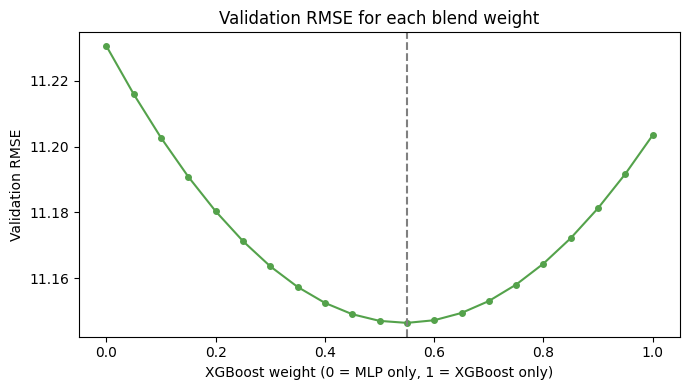

In [3]:
best_weight, weight_results = select_blend_weight(y_val, xgb_val, mlp_val, clip=True)
print(f"Selected weights: XGBoost = {best_weight:.2f}, MLP = {1 - best_weight:.2f}")
display(weight_results.round(4).iloc[::2])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(weight_results["xgb_weight"], weight_results["rmse"], marker="o", ms=4, color="#54A24B")
ax.axvline(best_weight, ls="--", color="grey")
ax.set_xlabel("XGBoost weight (0 = MLP only, 1 = XGBoost only)")
ax.set_ylabel("Validation RMSE")
ax.set_title("Validation RMSE for each blend weight")
fig.tight_layout()
plt.show()

The curve is very flat near its minimum: a weight anywhere from about 0.4 to 0.7 gives almost the same RMSE, so the exact value (0.55) is not important. What matters is that a mix is better than either end of the curve.

## 3. Effect of clipping to 0–100

CCME values cannot go outside 0–100, but a blend can. Clipping fixes impossible values. We check that it does not hurt.

In [4]:
raw = blend_predictions(xgb_val, mlp_val, best_weight)
clipped = clip_predictions(raw)
print("Predictions outside 0-100 before clipping:", int(((raw < 0) | (raw > 100)).sum()))
display(pd.DataFrame({"Raw blend": evaluate_predictions(y_val, raw),
                      "Clipped blend": evaluate_predictions(y_val, clipped)}).T.round(4))

Predictions outside 0-100 before clipping: 232


,mae,rmse,r2
Raw blend,7.6911,11.1468,0.3545
Clipped blend,7.6876,11.1465,0.3546


## 4. Save the hybrid predictions

Validation predictions are saved with the two inputs alongside, so they can be inspected. Test predictions use the same validation-selected weight and are **not scored here**.

In [5]:
hybrid_val = clip_predictions(blend_predictions(xgb_val, mlp_val, best_weight))
hybrid_test = clip_predictions(blend_predictions(xgb_test, mlp_test, best_weight))

weight_results.to_csv(RESULTS / "hybrid_blend_weights.csv", index=False)
pd.DataFrame({"row_id": val_ids, "y_true": y_val, "y_pred": hybrid_val,
              "xgb_pred": xgb_val, "mlp_pred": mlp_val, "blend_pred": hybrid_val}
             ).to_csv(RESULTS / "hybrid_val_preds.csv", index=False)
pd.DataFrame({"row_id": test_ids, "y_pred": hybrid_test}
             ).to_csv(RESULTS / "predictions_hybrid.csv", index=False)

print("Validation hybrid:", {k: round(v, 4) for k, v in evaluate_predictions(y_val, hybrid_val).items()})
print("Saved results/hybrid_blend_weights.csv, hybrid_val_preds.csv, predictions_hybrid.csv")
print("Test predictions saved without scoring the test set.")

Validation hybrid: {'mae': 7.6876, 'rmse': 11.1465, 'r2': 0.3546}
Saved results/hybrid_blend_weights.csv, hybrid_val_preds.csv, predictions_hybrid.csv
Test predictions saved without scoring the test set.


Correlation of validation errors, XGBoost vs MLP: 0.975


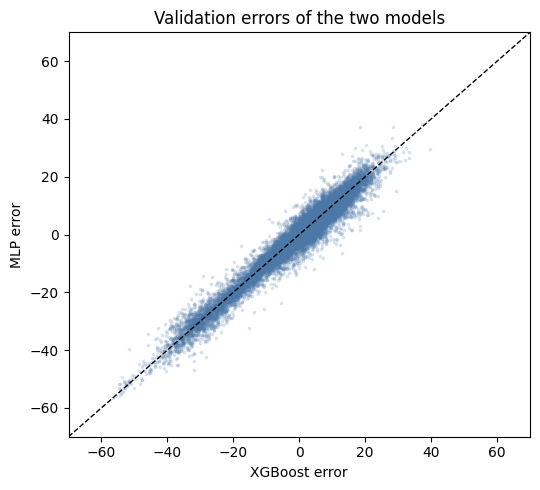

In [6]:
# Where do the two models disagree? The blend helps most when their errors differ.
xgb_err, mlp_err = y_val - xgb_val, y_val - mlp_val
print("Correlation of validation errors, XGBoost vs MLP:", round(float(np.corrcoef(xgb_err, mlp_err)[0, 1]), 3))

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(xgb_err, mlp_err, s=3, alpha=0.15, color="#4C78A8")
lim = [-70, 70]
ax.plot(lim, lim, "k--", lw=1)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("XGBoost error"); ax.set_ylabel("MLP error")
ax.set_title("Validation errors of the two models")
fig.tight_layout()
plt.show()

The errors are highly correlated, so the two models make mostly the same mistakes. That limits how much a blend can help, which matches the small gain seen in notebook 08.

## 5. Residual learning (tried and rejected)

A second hybrid: train an MLP to predict XGBoost's remaining error, then add that correction to XGBoost.

**This is where out-of-fold (OOF) predictions are needed.** XGBoost's predictions on its own training rows are too accurate, so residuals built from them would be too small. We build honest residual targets with 5-fold, station-grouped OOF predictions.

**Result.** The residual MLP's corrections had almost no correlation with the real residuals: about 0.088 on the station split (this experiment) and about −0.001 on the year split (notebook 08). The correction carried no useful signal, so we kept the weighted blend.

The cell below reruns the station-split experiment. It retrains XGBoost 5 times plus once on all training data, and trains a PyTorch MLP, so it needs `xgboost` and `torch` and takes several minutes. It is off by default.

In [7]:
RUN_RESIDUAL_EXPERIMENT = False

In [8]:
if RUN_RESIDUAL_EXPERIMENT:

    # 1. Imports and reproducibility

    import sys
    import os
    from pathlib import Path

    import numpy as np
    import pandas as pd
    import torch

    from sklearn.model_selection import GroupKFold
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
    from xgboost import XGBRegressor

    SEED = 42
    N_SPLITS = 5

    np.random.seed(SEED)
    torch.manual_seed(SEED)

    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

    os.chdir(ROOT)
    sys.path.insert(0, str(ROOT))

    print("Project root:", ROOT)
    print("Current working directory:", Path.cwd())
    print("PyTorch:", torch.__version__)
    print("OOF folds:", N_SPLITS)



    # 2. Load the project data and prepare features

    from src.features import (
        load_final_dataset,
        make_features,
        get_xy,
        build_preprocessor,
        FEATURE_COLS,
        TARGET_COL,
    )


    df = load_final_dataset()
    df = make_features(df)

    print("Dataset shape:", df.shape)
    print("\nSplit distribution:")
    print(df["split"].value_counts())

    print("\nNumber of unique stations:")
    print(df.groupby("split")["site_id"].nunique())

    print("\nFeature count:", len(FEATURE_COLS))
    print("Target:", TARGET_COL)



    # 3. Separate data by the original station-based split

    train_df = df[df["split"] == "train"].copy()
    val_df = df[df["split"] == "val"].copy()
    test_df = df[df["split"] == "test"].copy()

    # Raw model inputs
    X_train_raw = train_df[FEATURE_COLS].copy()
    X_val_raw = val_df[FEATURE_COLS].copy()
    X_test_raw = test_df[FEATURE_COLS].copy()

    # Target values
    y_train = train_df[TARGET_COL].to_numpy(dtype=np.float32)
    y_val = val_df[TARGET_COL].to_numpy(dtype=np.float32)
    y_test = test_df[TARGET_COL].to_numpy(dtype=np.float32)

    # Station IDs for leakage-safe GroupKFold
    groups_train = train_df["site_id"].to_numpy()

    # Row IDs for prediction alignment
    row_id_train = train_df["row_id"].to_numpy()
    row_id_val = val_df["row_id"].to_numpy()
    row_id_test = test_df["row_id"].to_numpy()

    # Verify station separation
    train_sites = set(train_df["site_id"])
    val_sites = set(val_df["site_id"])
    test_sites = set(test_df["site_id"])

    assert train_sites.isdisjoint(val_sites)
    assert train_sites.isdisjoint(test_sites)
    assert val_sites.isdisjoint(test_sites)

    assert len(X_train_raw) == len(y_train) == len(groups_train)
    assert len(X_val_raw) == len(y_val) == len(row_id_val)
    assert len(X_test_raw) == len(y_test) == len(row_id_test)

    print("Training shape:", X_train_raw.shape)
    print("Validation shape:", X_val_raw.shape)
    print("Test shape:", X_test_raw.shape)

    print("\nStation overlap:")
    print("Train / Validation:", len(train_sites & val_sites))
    print("Train / Test:", len(train_sites & test_sites))
    print("Validation / Test:", len(val_sites & test_sites))

    print("\nRow ID uniqueness:")
    print("Train:", len(np.unique(row_id_train)) == len(row_id_train))
    print("Validation:", len(np.unique(row_id_val)) == len(row_id_val))
    print("Test:", len(np.unique(row_id_test)) == len(row_id_test))


    # 4. Verify data alignment and station separation

    assert len(X_train_raw) == len(y_train) == len(row_id_train)
    assert len(X_val_raw) == len(y_val) == len(row_id_val)
    assert len(X_test_raw) == len(y_test) == len(row_id_test)

    assert len(groups_train) == len(X_train_raw)

    print("Training shape:", X_train_raw.shape)
    print("Validation shape:", X_val_raw.shape)
    print("Test shape:", X_test_raw.shape)

    print("\nStation overlap:")
    print("Train / Validation:", len(train_sites & val_sites))
    print("Train / Test:", len(train_sites & test_sites))
    print("Validation / Test:", len(val_sites & test_sites))

    print("\nRow ID uniqueness:")
    print("Train:", len(np.unique(row_id_train)) == len(row_id_train))
    print("Validation:", len(np.unique(row_id_val)) == len(row_id_val))
    print("Test:", len(np.unique(row_id_test)) == len(row_id_test))

    print("\nTraining stations:", len(np.unique(groups_train)))

    # 5. Define the Phase 1 XGBoost configuration

    XGB_PARAMS = {
        "objective": "reg:squarederror",
        "n_estimators": 300,
        "max_depth": 8,
        "learning_rate": 0.03,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 1,
        "random_state": SEED,
        "n_jobs": 1,             # Reduced parallelism to avoid resource overload
        "tree_method": "hist",
        "verbosity": 1,
    }

    print("XGBoost configuration:")
    print(XGB_PARAMS)

    print("\nNumber of OOF folds:", N_SPLITS)
    print("Unique training stations:", len(np.unique(groups_train)))


    # 6. Generate station-based out-of-fold XGBoost predictions

    oof_xgb = np.full(len(y_train), np.nan, dtype=np.float32)

    gkf = GroupKFold(n_splits=N_SPLITS)

    for fold, (fit_idx, holdout_idx) in enumerate(
        gkf.split(X_train_raw, y_train, groups=groups_train), start=1
    ):
        print(f"Training OOF fold {fold}/{N_SPLITS}")

        X_fit = X_train_raw.iloc[fit_idx]
        X_holdout = X_train_raw.iloc[holdout_idx]

        y_fit = y_train[fit_idx]

        # Fit preprocessing only on this fold's training rows
        preprocessor = build_preprocessor(scale=False)

        X_fit_processed = preprocessor.fit_transform(X_fit)
        X_holdout_processed = preprocessor.transform(X_holdout)

        model = XGBRegressor(**XGB_PARAMS)

        model.fit(X_fit_processed, y_fit)

        oof_xgb[holdout_idx] = model.predict(X_holdout_processed)

        print(
            "  Fold RMSE:",
            f"{np.sqrt(mean_squared_error(y_train[holdout_idx], oof_xgb[holdout_idx])):.4f}"
        )

    assert not np.isnan(oof_xgb).any()

    print("\nOOF predictions generated:", len(oof_xgb))
    print("OOF MAE:", mean_absolute_error(y_train, oof_xgb))
    print("OOF RMSE:", np.sqrt(mean_squared_error(y_train, oof_xgb)))
    print("OOF R²:", r2_score(y_train, oof_xgb))


    # 7. Train the full-training XGBoost model

    full_preprocessor = build_preprocessor(scale=False)

    X_train_processed = full_preprocessor.fit_transform(X_train_raw)
    X_val_processed = full_preprocessor.transform(X_val_raw)
    X_test_processed = full_preprocessor.transform(X_test_raw)

    xgb_full = XGBRegressor(**XGB_PARAMS)

    xgb_full.fit(X_train_processed, y_train)

    # Predictions for validation and test sets
    xgb_val_pred = xgb_full.predict(X_val_processed)
    xgb_test_pred = xgb_full.predict(X_test_processed)

    print("Full-training XGBoost model trained.")
    print("Validation predictions:", len(xgb_val_pred))
    print("Test predictions:", len(xgb_test_pred))

    print("\nValidation XGBoost metrics:")
    print("MAE:", mean_absolute_error(y_val, xgb_val_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_val, xgb_val_pred)))
    print("R²:", r2_score(y_val, xgb_val_pred))



    # 12. Calculate training residuals using OOF XGBoost predictions

    # Ensure predictions and actual values are aligned
    assert len(y_train) == len(oof_xgb)
    assert not np.isnan(oof_xgb).any()
    assert np.isfinite(oof_xgb).all()

    # Residual = Actual value - OOF XGBoost prediction
    residual_train = y_train - oof_xgb

    # Check residual targets
    print("Training residuals generated:", len(residual_train))
    print("Mean residual:", np.mean(residual_train))
    print("Residual standard deviation:", np.std(residual_train))
    print("Minimum residual:", np.min(residual_train))
    print("Maximum residual:", np.max(residual_train))

    # Verify there are no invalid values
    assert np.isfinite(residual_train).all()

    print("\nResidual target preparation: PASSED")


    # 13. Train residual MLP using OOF XGBoost residuals

    import copy
    import torch.nn as nn
    from torch.utils.data import TensorDataset, DataLoader
    from scipy import sparse

    # Validation residuals are used ONLY for early stopping.
    # They are not used to train/update the MLP weights.
    residual_val = np.asarray(y_val) - np.asarray(xgb_val_pred)

    # Standardise residual targets using TRAINING statistics only
    residual_mean = float(np.mean(residual_train))
    residual_std = float(np.std(residual_train))

    y_res_train_scaled = (residual_train - residual_mean) / residual_std
    y_res_val_scaled = (residual_val - residual_mean) / residual_std

    # Feature matrices for the residual MLP. These are scaled, unlike the
    # XGBoost inputs above (build_preprocessor(scale=False)), because a neural
    # network needs scaled inputs. Fitted on the training rows only. This gives
    # the same 30 input columns as the main MLP in notebook 06.
    res_preprocessor = build_preprocessor(scale=True)
    X_res_train = res_preprocessor.fit_transform(X_train_raw)
    X_res_val = res_preprocessor.transform(X_val_raw)

    print("Residual MLP input shapes:", X_res_train.shape, X_res_val.shape)

    # Convert sparse matrices to dense arrays if necessary
    if sparse.issparse(X_res_train):
        X_res_train = X_res_train.toarray()

    if sparse.issparse(X_res_val):
        X_res_val = X_res_val.toarray()

    X_res_train = np.asarray(X_res_train, dtype=np.float32)
    X_res_val = np.asarray(X_res_val, dtype=np.float32)

    # Convert to tensors
    X_train_tensor = torch.tensor(X_res_train, dtype=torch.float32)
    y_train_tensor = torch.tensor(
        y_res_train_scaled, dtype=torch.float32
    ).reshape(-1, 1)

    X_val_tensor = torch.tensor(X_res_val, dtype=torch.float32)
    y_val_tensor = torch.tensor(
        y_res_val_scaled, dtype=torch.float32
    ).reshape(-1, 1)

    train_loader = DataLoader(
        TensorDataset(X_train_tensor, y_train_tensor),
        batch_size=512,
        shuffle=True
    )

    # Residual MLP: same hidden-layer structure as tuned MLP
    class ResidualMLP(nn.Module):
        def __init__(self, input_dim):
            super().__init__()
            self.network = nn.Sequential(
                nn.Linear(input_dim, 128),
                nn.ReLU(),
                nn.Dropout(0.2),
                nn.Linear(128, 64),
                nn.ReLU(),
                nn.Dropout(0.2),
                nn.Linear(64, 1)
            )

        def forward(self, x):
            return self.network(x)

    torch.manual_seed(SEED)

    device = torch.device("cpu")

    residual_model = ResidualMLP(X_res_train.shape[1]).to(device)

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(
        residual_model.parameters(),
        lr=0.001,
        weight_decay=0.0001
    )

    best_val_loss = float("inf")
    best_state = None
    patience = 10
    epochs = 60
    epochs_without_improvement = 0

    for epoch in range(epochs):

        residual_model.train()
        train_losses = []

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            predictions = residual_model(xb)
            loss = criterion(predictions, yb)
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        # Validation: no gradient updates
        residual_model.eval()

        with torch.no_grad():
            val_predictions = residual_model(
                X_val_tensor.to(device)
            )
            val_loss = criterion(
                val_predictions,
                y_val_tensor.to(device)
            ).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(residual_model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if (epoch + 1) % 5 == 0:
            print(
                f"Epoch {epoch + 1:02d} | "
                f"Train loss: {np.mean(train_losses):.5f} | "
                f"Validation residual loss: {val_loss:.5f}"
            )

        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch + 1}")
            break

    # Restore the best validation checkpoint
    residual_model.load_state_dict(best_state)

    print("\nResidual MLP training completed.")
    print("Best validation residual loss:", best_val_loss)
    print("Input features:", X_res_train.shape[1])
    print("Device:", device)

    # 14. Check the residual targets and the trained model's predictions

    residual_model.eval()

    with torch.no_grad():
        train_res_pred_scaled = residual_model(
            torch.tensor(X_res_train, dtype=torch.float32).to(device)
        ).cpu().numpy().ravel()

        val_res_pred_scaled = residual_model(
            torch.tensor(X_res_val, dtype=torch.float32).to(device)
        ).cpu().numpy().ravel()

    # Convert predictions back to the original CCME scale
    train_res_pred = train_res_pred_scaled * residual_std + residual_mean
    val_res_pred = val_res_pred_scaled * residual_std + residual_mean

    print("TRAIN RESIDUALS")
    print("Actual mean:", np.mean(residual_train))
    print("Actual std:", np.std(residual_train))
    print("Predicted mean:", np.mean(train_res_pred))
    print("Predicted std:", np.std(train_res_pred))

    print("\nVALIDATION RESIDUALS")
    print("Actual mean:", np.mean(residual_val))
    print("Actual std:", np.std(residual_val))
    print("Predicted mean:", np.mean(val_res_pred))
    print("Predicted std:", np.std(val_res_pred))

    print("\nValidation residual correlation:",
          np.corrcoef(residual_val, val_res_pred)[0, 1])

    # 15. Diagnose residual target scaling and validation data

    print("TRAINING")
    print("Residual shape:", residual_train.shape)
    print("Residual mean:", np.mean(residual_train))
    print("Residual std:", np.std(residual_train))
    print("Scaled residual mean:", np.mean(y_res_train_scaled))
    print("Scaled residual std:", np.std(y_res_train_scaled))

    print("\nVALIDATION")
    print("y_val shape:", np.asarray(y_val).shape)
    print("XGB validation prediction shape:", np.asarray(xgb_val_pred).shape)
    print("Residual shape:", np.asarray(residual_val).shape)
    print("Residual mean:", np.mean(residual_val))
    print("Residual std:", np.std(residual_val))
    print("Scaled residual mean:", np.mean(y_res_val_scaled))
    print("Scaled residual std:", np.std(y_res_val_scaled))

    print("\nPREDICTIONS")
    print("Predicted validation residual std:", np.std(val_res_pred))
    print("Validation residual correlation:",
          np.corrcoef(residual_val, val_res_pred)[0, 1])